**Note for reviewers.** This notebook also contains analyses that are not reported in the paper: role-centroid and distribution-matched controls. History and interaction results are reported from targetted_analysis (history.json, interaction.json). Those sections are kept only so the notebook runs as one unit, and their outputs should not be read as paper results.

# New wd=0.1 benchmark follow-up (execution preparation)
Exploratory validation analysis; historical saved outputs cleared.
Historical numerical prose is background, not a result of this benchmark.
Output-key scrubbing does not establish a serial algorithm. MB16 legacy scrub results
are invalidated by F25; use Section R corrected results. No new test access is permitted.


# MB15 — Does the Window Matter, Is the Interaction About the Player, and Which Context Input Gates It?

**Track B · Follow-up to MB03–MB13 · Identity × Context project**

| Item | Content |
|---|---|
| **Questions** | (1) Is the model's p(a_id) calibrated on conflicts, so that "Δ exceeds the data log-odds" can be read correctly? (2) Does replacing the 15 earlier events, with the scored event held fixed, change Δ or the identity effect? (3) Is the C4 interaction specific to learned player content, or does a random vector of the same norm produce it too? (4) Which single context input changes how much the player matters? (5) Do C2, C3, C4 and the identity effect hold on genuine (non-coupled) events alone? (6) Does removing the player at inference change NLL? |
| **Population** | Validation only. Estimation half for every primary number; discovery half reported alongside. |
| **Status** | Follow-up after MB12; exploratory; not part of the MB12 lock. The plan is written and fingerprinted before any number. No test data. |
| **Outputs** | `config/MB15_plan.json`, `results/MB15_*` |

In [1]:
import os
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: False | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.patching as patching
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, patching, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)
import mi_src.conflict as conflict

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified_at_start = fingerprint.verify_files(MANIFEST)
manifest_before = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
assert IDENTITY == "player", "BLOCKED: MB14-MB16 follow up MB04-MB12, which studied the player variable."
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])


SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]
N_DRAWS = SETTINGS["n_draws"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
# No test view is built or read anywhere in MB14-MB16 (mi_setup.unlock_test_view is never called).
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
partners = pd.read_parquet(POP / "swap_partners.parquet")
donors = pd.read_parquet(POP / "context_donors.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
reference = torch.load(POP / "reference_means.pt", map_location="cpu", weights_only=False)
MEANS = {site: value.to(DEVICE) for site, value in reference["means"].items()}
REFERENCE_WINDOWS = np.asarray(reference["windows"])
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
ALL = circuits.all_components(N_LAYERS, N_HEADS)
FEATURES = list(bundle["encoded"].tensors.keys())
IDENTITY_FEATURES = [name for name in ["player", "team", "role", "competition"] if name in FEATURES]
CONTEXT_FEATURES = [name for name in FEATURES if name not in IDENTITY_FEATURES]

p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
p_player = p_player.merge(donors[["event_row", "donor_window"]], on="event_row", how="left")
discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
index0 = val_conflicts[val_conflicts.population == "index-0"].reset_index(drop=True)
print(f"verified files: {len(verified_at_start)} | primary seed {PRIMARY_SEED} | seeds {SEEDS}")
print(f"P-player rows: {len(p_player):,} (discovery {len(discovery):,}, estimation {len(estimation):,}) | "
      f"index-0: {len(index0):,} | matched controls: {len(controls):,}")
print(f"components: {ALL}")
print(f"identity inputs: {IDENTITY_FEATURES} | context inputs ({len(CONTEXT_FEATURES)}): {CONTEXT_FEATURES}")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 82 | primary seed 103 | seeds [100, 101, 102, 103, 104]
P-player rows: 1,744 (discovery 1,215, estimation 529) | index-0: 8,947 | matched controls: 252
components: ['L0H0', 'L0H1', 'L0MLP', 'L1H0', 'L1H1', 'L1MLP', 'L2H0', 'L2H1', 'L2MLP', 'L3H0', 'L3H1', 'L3MLP']
identity inputs: ['player', 'team', 'role', 'competition'] | context inputs (15): ['zone', 'period', 'minute_bin', 'score_diff', 'play_pattern', 'poss_len', 'possession_flag', 'prev_action', 'prev_outcome', 'prev_end_zone', 'same_player_as_prev', 'x_norm', 'y_norm', 'dt', 't_poss']


## 1. The plan (written before any number)

In [4]:
PLAN = {
    "status": "follow-up after MB12; exploratory; not part of the MB12 lock",
    "Q1_calibration": "mean p(a_id), p(a_ctx) vs realised shares on conflicts; model-implied pooled log-odds log(sum p_ctx / sum p_id) vs empirical log-odds; from MB03_event_scores (seed 103), no new model run",
    "Q2_history": ("three edits per P-all conflict, donor = another validation conflict from a different match scored at the same position (seed 0): "
                   "(a) donor's 15 earlier events, own scored event; (b) own earlier events, donor's context inputs at the scored event; "
                   "(c) donor window with own identity inputs at the scored event. Measures |change in Delta|, KL, and the identity effect under each"),
    "Q2_reading": "if (a) moves Delta by less than 10 per cent of (c), the window outside the scored event is read as negligible for arbitration",
    "Q3_interaction": ("2x2 factorial as MB04 E8 with player B = matched partner, B = norm-matched random vector (same direction in both contexts), "
                       "B = removed (index 0); |I| - |I_floor| for each; paired difference partner minus random vector"),
    "Q3_reading": "the interaction is called player-specific only if partner minus random-vector difference has CI above 0",
    "Q4_single_factor": ("2x2: player A vs partner B x one context input at the scored event, own value vs the MB02 donor's value; "
                         "inputs: every categorical and continuous context input; |I_f| - |I_f floor| with BH over inputs"),
    "Q5_strata": "I1 effect, C2, C3, C4 separately on genuine and coupled P-player events (estimation half; all validation as secondary)",
    "Q6_inference_removal": "NLL change on every scored validation event whose acting player has an embedding, player -> 0 at the target; also team -> 0, and player and team -> 0"
}
plan_path = OUT / "config" / "MB15_plan.json"
if plan_path.exists():
    stored = mi_setup.load_json(plan_path)
    changed = {key for key in PLAN if key != "written_at" and stored.get(key) != PLAN[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the plan in {plan_path.name} differs from this notebook in {sorted(changed)}. "
                           "A plan is written once, before results; delete the file only if no result was read.")
    PLAN = stored
    print("plan already written at", stored["written_at"], "- unchanged")
else:
    PLAN["written_at"] = fingerprint.now()
    mi_setup.save_json(plan_path, PLAN)
    print("plan written:", plan_path.name)
fingerprint.record_files(MANIFEST, {"config/MB15_plan.json": plan_path})
print(json.dumps({key: value for key, value in PLAN.items() if key != "written_at"}, indent=1))

plan written: MB15_plan.json
{
 "status": "follow-up after MB12; exploratory; not part of the MB12 lock",
 "Q1_calibration": "mean p(a_id), p(a_ctx) vs realised shares on conflicts; model-implied pooled log-odds log(sum p_ctx / sum p_id) vs empirical log-odds; from MB03_event_scores (seed 103), no new model run",
 "Q2_history": "three edits per P-all conflict, donor = another validation conflict from a different match scored at the same position (seed 0): (a) donor's 15 earlier events, own scored event; (b) own earlier events, donor's context inputs at the scored event; (c) donor window with own identity inputs at the scored event. Measures |change in Delta|, KL, and the identity effect under each",
 "Q2_reading": "if (a) moves Delta by less than 10 per cent of (c), the window outside the scored event is read as negligible for arbitration",
 "Q3_interaction": "2x2 factorial as MB04 E8 with player B = matched partner, B = norm-matched random vector (same direction in both contexts), B =

## 2. Q1 — Is p(a_id) calibrated on conflicts?

MB03 compared mean Δ (an average of per-event log-odds) with the pooled empirical log-odds. These are different quantities: even a perfectly calibrated model can have a mean per-event log-odds far above the pooled log-odds when p(a_id) is small and varies across events. The comparable model quantity is the **model-implied pooled log-odds**, log(Σ p(a_ctx) / Σ p(a_id)); the direct test is whether mean p(a_id) matches how often a_id happened.

In [5]:
event_scores = pd.read_parquet(OUT / "results" / "MB03_event_scores.parquet")
event_scores["p_ctx"] = np.exp(event_scores["log_p_ctx"])
event_scores["p_id"] = np.exp(event_scores["log_p_id"])
event_scores["is_ctx"] = (event_scores["action_id"] == event_scores["a_ctx"]).astype(float)
event_scores["is_id"] = (event_scores["action_id"] == event_scores["a_id"]).astype(float)


def calibration_row(name, frame):
    matches = frame["match_id"].to_numpy()
    unique = np.unique(matches)
    rng = np.random.default_rng(0)
    by_match = frame.groupby("match_id")[["p_ctx", "p_id", "is_ctx", "is_id"]].sum()
    counts = frame.groupby("match_id").size()

    def stats(rows):
        sums = by_match.loc[rows].sum()
        n = counts.loc[rows].sum()
        return {"mean p(a_id)": sums["p_id"] / n, "share a_id": sums["is_id"] / n,
                "mean p(a_ctx)": sums["p_ctx"] / n, "share a_ctx": sums["is_ctx"] / n,
                "model pooled log-odds": np.log(sums["p_ctx"] / sums["p_id"]),
                "empirical log-odds": np.log((sums["is_ctx"] + 0.5) / (sums["is_id"] + 0.5))}

    point = stats(unique)
    draws = pd.DataFrame([stats(rng.choice(unique, size=len(unique), replace=True)) for _ in range(N_BOOT)])
    row = {"subset": name, "n": len(frame), "mean Delta": float(frame["delta"].mean())}
    for key, value in point.items():
        row[key] = float(value)
    for key in ["mean p(a_id)", "share a_id", "model pooled log-odds", "empirical log-odds"]:
        row[f"{key} CI low"] = float(np.percentile(draws[key], 2.5))
        row[f"{key} CI high"] = float(np.percentile(draws[key], 97.5))
    gap = draws["model pooled log-odds"] - draws["empirical log-odds"]
    row["pooled log-odds gap (model - data)"] = float(point["model pooled log-odds"] - point["empirical log-odds"])
    row["gap CI low"], row["gap CI high"] = float(np.percentile(gap, 2.5)), float(np.percentile(gap, 97.5))
    return row


e = event_scores
subsets = [("P-all", e), ("P-all, estimation half", e[e.half == "estimation"]), ("P-player", e[e.population == "P-player"]),
           ("index-0", e[e.population == "index-0"]), ("genuine", e[e.genuine]), ("coupled", e[~e.genuine])]
calibration = pd.DataFrame([calibration_row(name, frame) for name, frame in subsets if len(frame)])
calibration.to_csv(OUT / "results" / "MB15_calibration.csv", index=False)
print(calibration.round(4).T.to_string())

                                         0                       1         2        3        4        5
subset                               P-all  P-all, estimation half  P-player  index-0  genuine  coupled
n                                    10691                    5180      1744     8947     5632     5059
mean Delta                          6.2499                  6.2093    5.9633   6.3058   5.0918   7.5392
mean p(a_id)                        0.0197                  0.0206     0.024   0.0189   0.0332   0.0047
share a_id                          0.0197                  0.0185    0.0189   0.0199   0.0357    0.002
mean p(a_ctx)                        0.863                  0.8631    0.8497   0.8656   0.7709   0.9655
share a_ctx                         0.8739                   0.878    0.8624   0.8762   0.7727   0.9866
model pooled log-odds               3.7804                  3.7342    3.5682   3.8267   3.1457    5.331
empirical log-odds                  3.7882                   3.8

## 3. Q2 — Does the window outside the scored event matter?

Each P-all conflict gets a donor: another validation conflict from a different match, scored at the same position (seed 0). Three edits, each checked to change only what it declares:

| Edit | Earlier events | Scored event: identity inputs | Scored event: context inputs |
|---|---|---|---|
| (a) history swap | donor's | own | own |
| (b) scored-event context swap | own | own | donor's |
| (c) whole-context swap | donor's | own | donor's |

If (a) moves Δ much less than (c), the arbitration is decided at the scored event, as MB06 suggested. The identity effect (Δ with minus without the player) is also measured under each edit: if it changes under (a), earlier events change how much the player matters even if they do not move Δ much on average.

In [6]:
p_all = val_conflicts.reset_index(drop=True).copy()
rng = np.random.default_rng(0)
by_position = {position: group for position, group in p_all.groupby("position")}
donor_rows = []
for index, row in p_all.iterrows():
    pool = by_position[row["position"]]
    pool = pool[pool["match_id"] != row["match_id"]]
    donor_rows.append(pool.iloc[rng.integers(len(pool))]["window"] if len(pool) else -1)
p_all["history_donor_window"] = np.array(donor_rows, dtype=np.int64)
p_all = p_all[p_all["history_donor_window"] >= 0].reset_index(drop=True)
print(f"P-all rows with a same-position donor from another match: {len(p_all):,} of {len(val_conflicts):,}")


def edit_inputs(kind, inputs, positions, donor_inputs):
    if kind == "history swap":
        changed = interventions.write_identity(donor_inputs, inputs, positions, FEATURES)
    elif kind == "scored-event context swap":
        changed = interventions.write_identity(inputs, donor_inputs, positions, CONTEXT_FEATURES)
        interventions.assert_scope(inputs, changed, CONTEXT_FEATURES, positions)
    else:
        changed = interventions.write_identity(donor_inputs, inputs, positions, IDENTITY_FEATURES)
    rows = torch.arange(len(positions), device=positions.device)
    for name in (FEATURES if kind == "history swap" else IDENTITY_FEATURES):
        assert torch.equal(changed[name][rows, positions], inputs[name][rows, positions]), (kind, name)
    return changed


EDITS = ["history swap", "scored-event context swap", "whole-context swap"]
records = []
with torch.no_grad():
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, p_all, BATCH):
        chunk = p_all.iloc[part]
        donor_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["history_donor_window"].to_numpy())
        base = mi_metrics.at_target(hooks.forward(MODEL, inputs)[0], positions)
        base_removed = mi_metrics.at_target(hooks.forward(MODEL, interventions.remove_feature(inputs, IDENTITY, positions))[0], positions)
        a_ctx_np, a_id_np = a_ctx.cpu().numpy(), a_id.cpu().numpy()
        frame = {"event_row": chunk["event_row"].to_numpy(), "match_id": chunk["match_id"].to_numpy(),
                 "half": chunk["half"].to_numpy(), "population": chunk["population"].to_numpy(),
                 "genuine": chunk["genuine"].to_numpy(),
                 "identity effect (own window)": mi_metrics.delta(base, a_ctx, a_id) - mi_metrics.delta(base_removed, a_ctx, a_id)}
        for kind in EDITS:
            changed = edit_inputs(kind, inputs, positions, donor_inputs)
            new = mi_metrics.at_target(hooks.forward(MODEL, changed)[0], positions)
            new_removed = mi_metrics.at_target(hooks.forward(MODEL, interventions.remove_feature(changed, IDENTITY, positions))[0], positions)
            frame[f"{kind}: |change in Delta|"] = np.abs(mi_metrics.delta(new, a_ctx, a_id) - mi_metrics.delta(base, a_ctx, a_id))
            frame[f"{kind}: KL"] = mi_metrics.kl_divergence(base.cpu().numpy(), new.cpu().numpy())
            frame[f"{kind}: identity effect"] = mi_metrics.delta(new, a_ctx, a_id) - mi_metrics.delta(new_removed, a_ctx, a_id)
        records.append(pd.DataFrame(frame))
history = pd.concat(records, ignore_index=True)
history.to_parquet(OUT / "results" / "MB15_history_edits.parquet", index=False)

rows = []
for subset, frame in [("P-all", history), ("P-all, estimation half", history[history.half == "estimation"]),
                      ("genuine", history[history.genuine]), ("coupled", history[~history.genuine])]:
    for kind in EDITS:
        change = mi_metrics.summarise(frame[f"{kind}: |change in Delta|"], frame["match_id"], N_BOOT)
        rows.append({"subset": subset, "edit": kind, "n": change["n"], "mean |change in Delta|": change["mean"],
                     "CI low": change["ci_low"], "CI high": change["ci_high"], "mean KL": float(frame[f"{kind}: KL"].mean())})
history_table = pd.DataFrame(rows)
whole = history_table[history_table.edit == "whole-context swap"].set_index("subset")["mean |change in Delta|"]
history_table["share of the whole-context swap"] = history_table["mean |change in Delta|"] / history_table["subset"].map(whole)
history_table.to_csv(OUT / "results" / "MB15_history.csv", index=False)
print(history_table.round(4).to_string(index=False))

player_rows = history[history.population == "P-player"]
identity_rows = []
for kind in ["own window"] + EDITS:
    column = "identity effect (own window)" if kind == "own window" else f"{kind}: identity effect"
    for half in ["estimation", "discovery"]:
        frame = player_rows[player_rows.half == half]
        signed = mi_metrics.summarise(frame[column], frame["match_id"], N_BOOT)
        absolute = mi_metrics.summarise(np.abs(frame[column]), frame["match_id"], N_BOOT)
        identity_rows.append({"window": kind, "half": half, "n": signed["n"], "mean identity effect (signed)": signed["mean"],
                              "CI low": signed["ci_low"], "CI high": signed["ci_high"],
                              "mean |identity effect|": absolute["mean"]})
identity_under_edits = pd.DataFrame(identity_rows)
identity_under_edits.to_csv(OUT / "results" / "MB15_identity_effect_under_edits.csv", index=False)
print()
print("Identity effect (Delta with player - Delta with player removed) on P-player rows, under each edit:")
print(identity_under_edits.round(4).to_string(index=False))

P-all rows with a same-position donor from another match: 10,688 of 10,691


                subset                      edit     n  mean |change in Delta|  CI low  CI high  mean KL  share of the whole-context swap
                 P-all              history swap 10688                  0.6323  0.6080   0.6549   0.0698                           0.0924
                 P-all scored-event context swap 10688                  6.8493  6.7230   6.9757   5.8788                           1.0009
                 P-all        whole-context swap 10688                  6.8434  6.7223   6.9631   5.9828                           1.0000
P-all, estimation half              history swap  5179                  0.6349  0.5994   0.6679   0.0769                           0.0941
P-all, estimation half scored-event context swap  5179                  6.7504  6.6094   6.8971   5.8772                           1.0007
P-all, estimation half        whole-context swap  5179                  6.7457  6.6104   6.8869   5.9827                           1.0000
               genuine            

## 4. Q3 — Is the identity × context interaction about the player?

MB04's 2 × 2 design is repeated with three choices of the second "player" B: the matched partner (as in MB04), a norm-matched random vector, and removal (index 0). The random vector has the same norm as player A's vector and the same direction in both contexts, so it changes the input by the same amount as a real swap but carries no learned player content. If the random vector produces as much interaction as the partner, C4 shows that the network is nonlinear, not that it gates *identity*.

In [7]:
units = p_player[p_player["donor_window"].notna()].copy()
units["donor_window"] = units["donor_window"].astype(int)
units["partner"] = [partner_of.get(p, -1) for p in units["player"]]
units = units[units["partner"] > 0].reset_index(drop=True)
FROZEN = [f"attn_out_{l}" for l in range(N_LAYERS)] + [f"mlp_out_{l}" for l in range(N_LAYERS)]


def fixed_random_vector(directions, positions):
    def edit(value):
        new = value.clone()
        rows = torch.arange(len(positions), device=value.device)
        norms = value[rows, positions].norm(dim=-1, keepdim=True)
        new[rows, positions] = directions * norms
        return new
    return edit


@torch.no_grad()
def factorial(table, second, seed=0):
    generator = torch.Generator().manual_seed(seed)
    rows_out = []
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        x_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        y_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE)
        a_id = torch.as_tensor(chunk["a_id"].to_numpy(), device=DEVICE)
        player_a = torch.as_tensor(chunk["player"].to_numpy(), device=DEVICE)
        directions = torch.randn((len(chunk), MODEL.ln_final.weight.shape[0]), generator=generator).to(DEVICE)
        directions = directions / directions.norm(dim=-1, keepdim=True)
        cells, floor = {}, {}
        for name, context in [("X", x_inputs), ("Y", y_inputs)]:
            with_a = interventions.set_feature(context, "player", positions, player_a)
            logits_a, cache_a = hooks.forward(MODEL, with_a, capture=FROZEN)
            replace_b = {}
            if second == "partner":
                with_b = interventions.set_feature(context, "player", positions,
                                                   torch.as_tensor(chunk["partner"].to_numpy(), device=DEVICE))
            elif second == "removed":
                with_b = interventions.remove_feature(context, "player", positions)
            else:
                with_b = with_a
                replace_b = {"factor_player": fixed_random_vector(directions, positions)}
            logits_b, _ = hooks.forward(MODEL, with_b, replace=replace_b)
            frozen = {site: (lambda value, kept=cache_a[site]: kept) for site in FROZEN}
            logits_b_floor, _ = hooks.forward(MODEL, with_b, replace={**replace_b, **frozen})
            cells[("A", name)] = mi_metrics.delta(mi_metrics.at_target(logits_a, positions), a_ctx, a_id)
            cells[("B", name)] = mi_metrics.delta(mi_metrics.at_target(logits_b, positions), a_ctx, a_id)
            floor[("B", name)] = mi_metrics.delta(mi_metrics.at_target(logits_b_floor, positions), a_ctx, a_id)
        interaction = cells[("A", "X")] - cells[("A", "Y")] - cells[("B", "X")] + cells[("B", "Y")]
        interaction_floor = cells[("A", "X")] - cells[("A", "Y")] - floor[("B", "X")] + floor[("B", "Y")]
        rows_out.append(pd.DataFrame({"event_row": chunk["event_row"].to_numpy(), "match_id": chunk["match_id"].to_numpy(),
                                      "half": chunk["half"].to_numpy(), "genuine": chunk["genuine"].to_numpy(),
                                      "I": interaction, "I_floor": interaction_floor,
                                      "main effect of B in X": cells[("A", "X")] - cells[("B", "X")]}))
    return pd.concat(rows_out, ignore_index=True)


factorials = {second: factorial(units, second) for second in ["partner", "random vector", "removed"]}
interaction_rows = []
for half in ["estimation", "discovery"]:
    for second, frame in factorials.items():
        part = frame[frame.half == half]
        beyond = np.abs(part["I"]) - np.abs(part["I_floor"])
        summary = mi_metrics.summarise(beyond, part["match_id"], N_BOOT)
        interaction_rows.append({"half": half, "player B": second, "units": summary["n"],
                                 "mean |I|": float(np.abs(part["I"]).mean()), "mean |I_floor|": float(np.abs(part["I_floor"]).mean()),
                                 "mean |I| - |I_floor|": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"],
                                 "mean |main effect of B|": float(np.abs(part["main effect of B in X"]).mean())})
    partner = factorials["partner"][factorials["partner"].half == half]
    random_vector = factorials["random vector"][factorials["random vector"].half == half]
    difference = (np.abs(partner["I"].to_numpy()) - np.abs(partner["I_floor"].to_numpy())) - \
                 (np.abs(random_vector["I"].to_numpy()) - np.abs(random_vector["I_floor"].to_numpy()))
    summary = mi_metrics.summarise(difference, partner["match_id"], N_BOOT)
    interaction_rows.append({"half": half, "player B": "partner minus random vector (paired)", "units": summary["n"],
                             "mean |I| - |I_floor|": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"]})
    ratio = (np.abs(partner["I"]) / (np.abs(partner["main effect of B in X"]) + 1e-9)).median()
    print(f"{half}: median |I| / |main effect of the partner swap| = {ratio:.3f}")
interaction = pd.DataFrame(interaction_rows)
interaction.to_csv(OUT / "results" / "MB15_interaction_controls.csv", index=False)
print(interaction.round(4).to_string(index=False))

estimation: median |I| / |main effect of the partner swap| = 1.164
discovery: median |I| / |main effect of the partner swap| = 1.206
      half                             player B  units  mean |I|  mean |I_floor|  mean |I| - |I_floor|  CI low  CI high  mean |main effect of B|
estimation                              partner    529    0.8307          0.0438                0.7869  0.7171   0.8793                   0.6561
estimation                        random vector    529    0.9718          0.0406                0.9311  0.8314   0.9939                   0.8239
estimation                              removed    529    0.6232          0.0298                0.5935  0.5171   0.6565                   0.5201
estimation partner minus random vector (paired)    529       NaN             NaN               -0.1442 -0.2427  -0.0152                      NaN
 discovery                              partner   1187    0.7683          0.0415                0.7268  0.6472   0.8361                   0.62

## 5. Q4 — Which single context input changes the player's effect?

For each context input f: players A (own) and B (matched partner) × input f at its own value or at the MB02 context donor's value (same role and scoring position, another match), with everything else of the event's own window unchanged. The interaction I_f measures how much changing that one input changes the effect of the player swap. The floor freezes every attention and MLP output at the A-run, as in MB04. Benjamini–Hochberg over inputs on the one-sided p-value of |I_f| − |I_f floor|.

Using the donor's value keeps every edit on the data distribution (unlike a ±1 SD shift).

In [8]:
@torch.no_grad()
def single_factor(table, feature):
    rows_out = []
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        x_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        y_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE)
        a_id = torch.as_tensor(chunk["a_id"].to_numpy(), device=DEVICE)
        player_b = torch.as_tensor(chunk["partner"].to_numpy(), device=DEVICE)
        rows = torch.arange(len(positions), device=DEVICE)
        x_f = interventions.set_feature(x_inputs, feature, positions, y_inputs[feature][rows, positions])
        interventions.assert_scope(x_inputs, x_f, [feature], positions)
        unchanged = (x_f[feature][rows, positions] == x_inputs[feature][rows, positions]).cpu().numpy()
        cells, floor = {}, {}
        for name, context in [("own", x_inputs), ("donor value", x_f)]:
            logits_a, cache_a = hooks.forward(MODEL, context, capture=FROZEN)
            with_b = interventions.set_feature(context, "player", positions, player_b)
            logits_b, _ = hooks.forward(MODEL, with_b)
            frozen = {site: (lambda value, kept=cache_a[site]: kept) for site in FROZEN}
            logits_b_floor, _ = hooks.forward(MODEL, with_b, replace=frozen)
            cells[("A", name)] = mi_metrics.delta(mi_metrics.at_target(logits_a, positions), a_ctx, a_id)
            cells[("B", name)] = mi_metrics.delta(mi_metrics.at_target(logits_b, positions), a_ctx, a_id)
            floor[("B", name)] = mi_metrics.delta(mi_metrics.at_target(logits_b_floor, positions), a_ctx, a_id)
        interaction = cells[("A", "own")] - cells[("A", "donor value")] - cells[("B", "own")] + cells[("B", "donor value")]
        interaction_floor = cells[("A", "own")] - cells[("A", "donor value")] - floor[("B", "own")] + floor[("B", "donor value")]
        rows_out.append(pd.DataFrame({"match_id": chunk["match_id"].to_numpy(), "half": chunk["half"].to_numpy(),
                                      "unchanged": unchanged, "I": interaction, "I_floor": interaction_floor,
                                      "main effect of f": cells[("A", "own")] - cells[("A", "donor value")]}))
    return pd.concat(rows_out, ignore_index=True)


factor_rows = []
for feature in CONTEXT_FEATURES:
    frame = single_factor(units, feature)
    for half in ["estimation", "discovery"]:
        part = frame[(frame.half == half) & ~frame["unchanged"]]
        if len(part) == 0:
            continue
        beyond = np.abs(part["I"]) - np.abs(part["I_floor"])
        summary = mi_metrics.summarise(beyond, part["match_id"], N_BOOT)
        factor_rows.append({"input": feature, "half": half, "units where the value differs": summary["n"],
                            "mean |main effect of the input|": float(np.abs(part["main effect of f"]).mean()),
                            "mean |I_f|": float(np.abs(part["I"]).mean()), "mean |I_f floor|": float(np.abs(part["I_floor"]).mean()),
                            "mean |I_f| - |floor|": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"],
                            "p (greater)": mi_metrics.bootstrap_pvalue(beyond, part["match_id"], N_BOOT, alternative="greater")})
single = pd.DataFrame(factor_rows)
for half, group in single.groupby("half"):
    single.loc[group.index, "q (BH over inputs)"] = mi_metrics.benjamini_hochberg(group["p (greater)"].to_numpy(), 0.05)[1]
single = single.sort_values(["half", "mean |I_f| - |floor|"], ascending=[False, False])
single.to_csv(OUT / "results" / "MB15_single_factor_interactions.csv", index=False)
print(single.round(4).to_string(index=False))

              input       half  units where the value differs  mean |main effect of the input|  mean |I_f|  mean |I_f floor|  mean |I_f| - |floor|  CI low  CI high  p (greater)  q (BH over inputs)
same_player_as_prev estimation                            215                           3.9092      1.1545            0.0574                1.0971  1.0012   1.2202       0.0005              0.0005
    possession_flag estimation                            256                           4.7390      1.1347            0.0444                1.0903  0.8707   1.2943       0.0005              0.0005
                 dt estimation                            431                           4.5585      0.7623            0.0382                0.7241  0.5602   0.8774       0.0005              0.0005
        prev_action estimation                            471                           3.5881      0.7097            0.0334                0.6764  0.5771   0.7581       0.0005              0.0005
       prev_out

## 6. Q5 — Do the identity results hold on genuine events alone?

Nearly half of the conflict set is coupled with the previous event, where the recorded sequence almost fixes the action. The identity effect, C2, C3 and C4 are recomputed separately on genuine and coupled P-player events. C3 uses the player-only reference exactly as MB04 does.

In [9]:
idplayer_state = torch.load(OUT / "artifacts" / "conflict" / "references" / "id_player_seed0.pt", map_location="cpu", weights_only=False)
idplayer = conflict.IdPlayer(idplayer_state["vocabulary_sizes"])
idplayer.load_state_dict(idplayer_state["state"])
with torch.no_grad():
    all_players = torch.arange(idplayer_state["vocabulary_sizes"]["player"])
    habit_log_probs = torch.log_softmax(idplayer(all_players.unsqueeze(1), torch.zeros(len(all_players), 0))
                                        / idplayer_state["temperature"], dim=-1).numpy()


def centred_log_probs(logits):
    values = mi_metrics.log_softmax(logits.cpu().numpy())
    return values - values.mean(1, keepdims=True)


@torch.no_grad()
def identity_measures(table, seed=0):
    generator = torch.Generator().manual_seed(seed)
    frames = []
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        chunk = table.iloc[part]
        own = chunk["player"].to_numpy()
        partner = np.array([partner_of.get(p, -1) for p in own])
        valid = partner > 0
        base = mi_metrics.at_target(hooks.forward(MODEL, inputs)[0], positions)
        removed = mi_metrics.at_target(hooks.forward(MODEL, interventions.remove_feature(inputs, IDENTITY, positions))[0], positions)
        swapped_inputs = interventions.set_feature(inputs, "player", positions, torch.as_tensor(np.where(valid, partner, own), device=DEVICE))
        swapped = mi_metrics.at_target(hooks.forward(MODEL, swapped_inputs)[0], positions)
        vector_change = []
        for _ in range(N_DRAWS):
            edit = interventions.norm_matched_vector(None, positions, generator)
            logits = mi_metrics.at_target(hooks.forward(MODEL, inputs, replace={"factor_player": edit})[0], positions)
            vector_change.append(np.abs(mi_metrics.delta(logits, a_ctx, a_id) - mi_metrics.delta(base, a_ctx, a_id)))
        d_base = mi_metrics.delta(base, a_ctx, a_id)
        model_change = centred_log_probs(swapped) - centred_log_probs(base)
        reference_change = habit_log_probs[np.where(valid, partner, own)] - habit_log_probs[own]
        reference_change = reference_change - reference_change.mean(1, keepdims=True)
        r = (model_change * reference_change).sum(1) / (np.sqrt((model_change ** 2).sum(1) * (reference_change ** 2).sum(1)) + 1e-12)
        frames.append(pd.DataFrame({"match_id": chunk["match_id"].to_numpy(), "half": chunk["half"].to_numpy(),
                                    "genuine": chunk["genuine"].to_numpy(),
                                    "identity effect": d_base - mi_metrics.delta(removed, a_ctx, a_id),
                                    "C2 difference": np.where(valid, np.abs(mi_metrics.delta(swapped, a_ctx, a_id) - d_base)
                                                              - np.mean(vector_change, 0), np.nan),
                                    "C3 r": np.where(valid, r, np.nan)}))
    return pd.concat(frames, ignore_index=True)


measures = identity_measures(p_player)
c4 = factorials["partner"].assign(beyond=lambda f: np.abs(f["I"]) - np.abs(f["I_floor"]))
strata_rows = []
for half_name, half_filter in [("estimation", ["estimation"]), ("all validation", ["estimation", "discovery"])]:
    for stratum, flag in [("genuine", True), ("coupled", False)]:
        frame = measures[measures.half.isin(half_filter) & (measures.genuine == flag)]
        c4_part = c4[c4.half.isin(half_filter) & (c4.genuine == flag)]
        row = {"rows": half_name, "stratum": stratum, "n": len(frame)}
        for column in ["identity effect", "C2 difference", "C3 r"]:
            values = frame[column].dropna()
            summary = mi_metrics.summarise(values, frame.loc[values.index, "match_id"], N_BOOT)
            row[f"{column}: mean"], row[f"{column}: CI low"], row[f"{column}: CI high"] = summary["mean"], summary["ci_low"], summary["ci_high"]
        row["|identity effect|: mean"] = float(np.abs(frame["identity effect"]).mean())
        summary = mi_metrics.summarise(c4_part["beyond"], c4_part["match_id"], N_BOOT)
        row["C4 |I| - |I_floor|: mean"], row["C4: CI low"], row["C4: CI high"] = summary["mean"], summary["ci_low"], summary["ci_high"]
        strata_rows.append(row)
strata = pd.DataFrame(strata_rows)
strata.to_csv(OUT / "results" / "MB15_strata.csv", index=False)
print(strata.round(4).T.to_string())

                                   0           1               2               3
rows                      estimation  estimation  all validation  all validation
stratum                      genuine     coupled         genuine         coupled
n                                282         247             914             830
identity effect: mean        -0.1657     -0.1689         -0.1429         -0.1205
identity effect: CI low      -0.2503     -0.3144         -0.1998         -0.2272
identity effect: CI high     -0.0657     -0.0164         -0.0818         -0.0077
C2 difference: mean          -0.0341     -0.1501         -0.0097         -0.2905
C2 difference: CI low        -0.0883       -0.29         -0.0441         -0.3675
C2 difference: CI high        0.0347      0.0406          0.0269         -0.1982
C3 r: mean                    0.1033      0.0444          0.1194          0.0536
C3 r: CI low                   0.029     -0.0051           0.067          0.0172
C3 r: CI high               

## 7. Q6 — Does removing the player at inference change NLL?

Section 6 of the paper compares models *retrained* without player and team. This asks the inference-time question for SEL-4L itself: on every scored validation event whose acting player has an embedding, how does the NLL of the true action change when the player (or team, or both) is set to index 0 at the scored event? A negative change means the model predicts better without the input.

In [10]:
scored = circuits.scored_events(val_view, targets, bundle["match_ids"],
                                limit=None if RUN_MODE == "full" else SETTINGS["max_events"] * 3)
conflict_rows = set(val_conflicts["event_row"])
nll_frames = []
with torch.no_grad():
    for part, inputs, positions, action, _ in mi_setup.event_batches(bundle, val_view, scored, BATCH):
        chunk = scored.iloc[part]
        rows = torch.arange(len(positions), device=DEVICE)
        has_player = (inputs["player"][rows, positions] > 0).cpu().numpy()

        def nll(changed):
            log_probs = torch.log_softmax(mi_metrics.at_target(hooks.forward(MODEL, changed)[0], positions), dim=-1)
            return (-log_probs[rows, action]).cpu().numpy()

        base = nll(inputs)
        no_player = interventions.remove_feature(inputs, "player", positions)
        no_team = interventions.remove_feature(inputs, "team", positions)
        no_both = interventions.remove_feature(no_player, "team", positions)
        nll_frames.append(pd.DataFrame({"match_id": chunk["match_id"].to_numpy(), "has_player": has_player,
                                        "conflict": chunk["event_row"].isin(conflict_rows).to_numpy(),
                                        "player -> 0": nll(no_player) - base, "team -> 0": nll(no_team) - base,
                                        "player and team -> 0": nll(no_both) - base}))
nll_changes = pd.concat(nll_frames, ignore_index=True)
nll_rows = []
for subset, frame in [("events with a dedicated player", nll_changes[nll_changes.has_player]),
                      ("  of which conflicts", nll_changes[nll_changes.has_player & nll_changes.conflict]),
                      ("  of which non-conflicts", nll_changes[nll_changes.has_player & ~nll_changes.conflict]),
                      ("all scored events (team change only meaningful)", nll_changes)]:
    for column in ["player -> 0", "team -> 0", "player and team -> 0"]:
        summary = mi_metrics.summarise(frame[column], frame["match_id"], N_BOOT)
        nll_rows.append({"events": subset, "change at the scored event": column, "n": summary["n"],
                         "mean NLL change": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"]})
inference_removal = pd.DataFrame(nll_rows)
inference_removal.to_csv(OUT / "results" / "MB15_inference_removal_nll.csv", index=False)
print(inference_removal.round(5).to_string(index=False))

                                         events change at the scored event     n  mean NLL change   CI low  CI high
                 events with a dedicated player                player -> 0 13891          0.00133 -0.00473  0.00616
                 events with a dedicated player                  team -> 0 13891          0.00738  0.00184  0.01270
                 events with a dedicated player       player and team -> 0 13891          0.00547 -0.00329  0.01303
                             of which conflicts                player -> 0  1744         -0.00974 -0.02435  0.00289
                             of which conflicts                  team -> 0  1744         -0.00350 -0.01536  0.00640
                             of which conflicts       player and team -> 0  1744         -0.01952 -0.03182 -0.00895
                         of which non-conflicts                player -> 0 12147          0.00292 -0.00355  0.00815
                         of which non-conflicts                  team ->

## 8. Additions from the deep MI audit: what does "identity" mean here?

The audit found four questions that decide how the identity results can be read. Each has a test that could prove the current reading wrong:

| ID | Question | Test | What would change the reading |
|---|---|---|---|
| **N1** | Is the "identity" effect about this player, or about the player's role? | replace the player's vector by the **average vector of players in the same role** (role centroid) | if most of the removal effect survives the centroid, the effect is mostly role |
| **N4** | Is C2 still negative with a control that looks like a real player? | **distribution-matched deviation**: role centroid + another same-role player's deviation, rescaled to this player's; also **shuffled coordinates** and a **same-team, same-role swap** | if a real partner moves Δ more than a realistic fake, C2's negative result came from an unrealistic control |
| **N2** | Is the per-event identity effect the same across the five training seeds? | correlate per-event effects across seeds | if it does not replicate, there is no stable player mechanism to find a circuit for |
| **N3** | Does anything change when the identity side is the player's **over-used** action instead of the default pass? | a_lift = the action the identity reference raises most above the base rate; Δ′ = logit(a_ctx) − logit(a_lift) | if C1–C4 or the patching profile differ on Δ′, the current results are about "situation vs base rate", not "situation vs player" |
| **N6** | Do results differ for players with fewer vs more training events? | stratify by < 1,000 vs ≥ 1,000 training events | |
| **N11** | Does the model handle (player, previous action) pairs it rarely saw in training? | identity effect by the training count of that pair | |

In [11]:
PLAN = {
    "status": "follow-up after the deep MI audit; exploratory; not part of the MB12 lock",
    "N1_role_centroid": ("player vector at the scored position -> mean player vector of the player's modal training role. "
                         "player-specific share = pooled sign-aligned (Delta own - Delta centroid) / (Delta own - Delta removed)"),
    "N1_reading": "the identity effect is called mostly role if the player-specific share CI lies below 0.5; mostly player-specific if above 0.5",
    "N4_controls": ["distribution-matched deviation (centroid + another same-role player's deviation rescaled to this player's deviation norm)",
                    "shuffled coordinates of the player's own vector", "same role AND same modal team swap (nearest log training count)",
                    "norm-matched random vector (as MB04 I4)"],
    "N4_reading": "C2 is re-read as player-specific only if |partner change| - |distribution-matched change| has CI above 0",
    "N2_cross_seed": ("per-event removal effect, partner-swap change and Delta under each of the 5 seeds on all P-player validation events; "
                      "mean pairwise Pearson correlation with match-resampled CI; player-level means for players with >= 5 events"),
    "N2_reading": "reproducible per event if the mean pairwise correlation CI lies above 0.5; not reproducible if it lies below 0.3",
    "N3_lift": ("a_lift = argmax over actions other than a_ctx of p_IdFull(action) / training base rate(action); "
                "Delta' = logit(a_ctx) - logit(a_lift); C1, identity effect, C2 and C4 (partner and random vector) on Delta'; "
                "identity-removal patching profile at the scored position on Delta and Delta' (estimation half)"),
    "N3_reading": "the profile is called the same if the per-site recoveries for Delta and Delta' correlate above 0.9 and no site differs by more than 0.2",
    "N6_bands": "acting player's training events < 1,000 vs >= 1,000: identity effect, C2 (random and distribution-matched), C4, patching profile",
    "N11_cells": "training count of the (player, previous action) pair: 0, 1-9, 10-49, >= 50; Delta, identity effect, |partner change| per bin; rare (0-9) minus common (>= 50) with match-resampled CI"
}
plan_path = OUT / "config" / "MB15_ext_plan.json"
if plan_path.exists():
    stored = mi_setup.load_json(plan_path)
    changed = {key for key in PLAN if key != "written_at" and stored.get(key) != PLAN[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the plan in {plan_path.name} differs from this notebook in {sorted(changed)}. "
                           "A plan is written once, before results; delete the file only if no result was read.")
    PLAN = stored
    print("plan already written at", stored["written_at"], "- unchanged")
else:
    PLAN["written_at"] = fingerprint.now()
    mi_setup.save_json(plan_path, PLAN)
    print("plan written:", plan_path.name)
fingerprint.record_files(MANIFEST, {"config/MB15_ext_plan.json": plan_path})
print(json.dumps({key: value for key, value in PLAN.items() if key != "written_at"}, indent=1))

plan written: MB15_ext_plan.json
{
 "status": "follow-up after the deep MI audit; exploratory; not part of the MB12 lock",
 "N1_role_centroid": "player vector at the scored position -> mean player vector of the player's modal training role. player-specific share = pooled sign-aligned (Delta own - Delta centroid) / (Delta own - Delta removed)",
 "N1_reading": "the identity effect is called mostly role if the player-specific share CI lies below 0.5; mostly player-specific if above 0.5",
 "N4_controls": [
  "distribution-matched deviation (centroid + another same-role player's deviation rescaled to this player's deviation norm)",
  "shuffled coordinates of the player's own vector",
  "same role AND same modal team swap (nearest log training count)",
  "norm-matched random vector (as MB04 I4)"
 ],
 "N4_reading": "C2 is re-read as player-specific only if |partner change| - |distribution-matched change| has CI above 0",
 "N2_cross_seed": "per-event removal effect, partner-swap change and Del

In [12]:
# Per-player facts from the TRAINING split, in the model's own (T300) player indices:
# modal role, modal team, number of training events. Used for frequency bands, role centroids and
# team-matched partners. Nothing here reads validation labels.
ENCODED = bundle["encoded"].tensors
assert len(ENCODED["player"]) == len(events), "BLOCKED: encoded tensors are not one row per event."
assert "split" in events.columns, "BLOCKED: events has no split column, so training counts cannot be computed."
TRAIN_ROWS = np.where(events["split"].to_numpy() == "train")[0]
_train = pd.DataFrame({name: ENCODED[name][torch.as_tensor(TRAIN_ROWS, device=ENCODED[name].device)].cpu().numpy()
                       for name in ["player", "role", "team"]})
_train = _train[_train["player"] > 0]
PLAYER_META = _train.groupby("player").agg(role=("role", lambda s: s.value_counts().index[0]),
                                           team=("team", lambda s: s.value_counts().index[0]),
                                           train_events=("role", "size"))
FREQUENCY_CUT = 1000


def frequency_band(players):
    counts = PLAYER_META["train_events"].reindex(np.asarray(players)).to_numpy()
    return np.where(np.isnan(counts), "no training events",
                    np.where(counts >= FREQUENCY_CUT, f">= {FREQUENCY_CUT} training events", f"< {FREQUENCY_CUT} training events"))


PLAYER_TABLE = MODEL.embedding.embeddings["player"].weight.detach()
ROLE_CENTROID = {int(role): PLAYER_TABLE[torch.as_tensor(group.index.to_numpy(), device=PLAYER_TABLE.device)].mean(0)
                 for role, group in PLAYER_META.groupby("role")}
print(f"players with training events: {len(PLAYER_META)} | roles: {len(ROLE_CENTROID)} | "
      f"frequency bands: {pd.Series(frequency_band(PLAYER_META.index)).value_counts().to_dict()}")


def player_vector_edit(new_vectors, players, positions):
    """Edit for site factor_player: at the scored position, swap the player's own embedding for new_vectors.

    The factor site is the sum of the group's embeddings; subtracting the player's own row and adding the new
    vector changes only the player part, whatever else the group contains."""
    own = PLAYER_TABLE[torch.as_tensor(np.asarray(players), device=PLAYER_TABLE.device)]

    def edit(value):
        new = value.clone()
        rows = torch.arange(len(positions), device=value.device)
        new[rows, positions] = value[rows, positions] - own.to(value.device) + new_vectors.to(value.device)
        return new
    return edit


def control_vectors(players, kind, rng):
    """Replacement player vectors for the identity controls (rows whose control is undefined get NaN)."""
    players = np.asarray(players)
    out = torch.full((len(players), PLAYER_TABLE.shape[1]), float("nan"), device=PLAYER_TABLE.device)
    for i, player in enumerate(players):
        if player not in PLAYER_META.index:
            continue
        role = int(PLAYER_META.loc[player, "role"])
        centroid = ROLE_CENTROID[role]
        own = PLAYER_TABLE[player]
        if kind == "role centroid":
            out[i] = centroid
        elif kind == "distribution-matched deviation":
            others = PLAYER_META.index[(PLAYER_META["role"] == role) & (PLAYER_META.index != player)
                                       & (PLAYER_META.index != partner_of.get(player, -1))].to_numpy()
            if len(others) == 0:
                continue
            other = PLAYER_TABLE[int(rng.choice(others))] - centroid
            out[i] = centroid + other * (own - centroid).norm() / (other.norm() + 1e-12)
        elif kind == "shuffled coordinates":
            out[i] = own[torch.as_tensor(rng.permutation(len(own)), device=own.device)]
        else:
            raise ValueError(kind)
    return out


def team_matched_partner(player):
    """Same modal role AND team, nearest log training count; -1 if none."""
    if player not in PLAYER_META.index:
        return -1
    row = PLAYER_META.loc[player]
    pool = PLAYER_META[(PLAYER_META["role"] == row["role"]) & (PLAYER_META["team"] == row["team"])
                       & (PLAYER_META.index != player)]
    if len(pool) == 0:
        return -1
    gap = np.abs(np.log(pool["train_events"].to_numpy()) - np.log(row["train_events"]))
    return int(pool.index[np.lexsort((pool.index.to_numpy(), gap))[0]])

import itertools
import warnings
N_BOOT_CORR = min(N_BOOT, 1000)


def delta_of(model, inputs, positions, a_ctx, a_other, replace=None):
    return circuits.delta_under(model, inputs, positions, a_ctx, a_other, replace)


def group_difference(values, groups, first, second, match_ids, n, seed=0):
    """Mean(values | first) - mean(values | second) with a match-resampled 95% interval."""
    values, groups, match_ids = np.asarray(values, float), np.asarray(groups), np.asarray(match_ids)
    a, b = groups == first, groups == second
    point = values[a].mean() - values[b].mean() if a.any() and b.any() else np.nan
    matches = np.unique(match_ids)
    rows_of = {m: np.where(match_ids == m)[0] for m in matches}
    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n):
        rows = np.concatenate([rows_of[m] for m in rng.choice(matches, len(matches))])
        va, vb = values[rows][a[rows]], values[rows][b[rows]]
        if len(va) and len(vb):
            draws.append(va.mean() - vb.mean())
    low, high = (np.percentile(draws, [2.5, 97.5]) if draws else (np.nan, np.nan))
    return {"difference": float(point), "CI low": float(low), "CI high": float(high)}

players with training events: 350 | roles: 23 | frequency bands: {'< 1000 training events': 333, '>= 1000 training events': 17}


## 9. N1 and N4 — role centroid and realistic controls

Every edit acts on the player's embedding at the scored position only (site `factor_player`). For each P-player event:

| Edit | What it keeps | What it removes |
|---|---|---|
| removed (index 0) | nothing of the player | everything |
| role centroid | what players of this role share | what is specific to this player |
| matched partner (MB04) | role, competition, similar frequency | this player's specifics |
| same role and team | role and team | this player's specifics |
| distribution-matched deviation | role part; a deviation of realistic size and shape | this player's deviation |
| shuffled coordinates | norm and value distribution | the learned direction |
| norm-matched random vector | norm | everything learned |

The removal effect splits exactly into a **player-specific part**, Δ(own) − Δ(centroid), and a **role part**, Δ(centroid) − Δ(removed).

In [13]:
CONTROL_KINDS = ["role centroid", "distribution-matched deviation", "shuffled coordinates"]
RANDOM_KINDS = ["distribution-matched deviation", "shuffled coordinates"]


@torch.no_grad()
def identity_controls(model, table, a_other_column="a_id", seed=0):
    rng = np.random.default_rng(seed)
    generator = torch.Generator().manual_seed(seed)
    frames = []
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE)
        a_other = torch.as_tensor(chunk[a_other_column].to_numpy(), device=DEVICE)
        own = chunk["player"].to_numpy()
        d = lambda changed, replace=None: delta_of(model, changed, positions, a_ctx, a_other, replace)
        base = d(inputs)
        frame = {"event_row": chunk["event_row"].to_numpy(), "match_id": chunk["match_id"].to_numpy(),
                 "half": chunk["half"].to_numpy(), "genuine": chunk["genuine"].to_numpy(), "player": own, "Delta": base,
                 "removal effect": base - d(interventions.remove_feature(inputs, IDENTITY, positions))}
        for name, others in [("partner", np.array([partner_of.get(p, -1) for p in own])),
                             ("same role and team", np.array([team_matched_partner(p) for p in own]))]:
            valid = others > 0
            changed = interventions.set_feature(inputs, "player", positions, torch.as_tensor(np.where(valid, others, own), device=DEVICE))
            frame[f"{name}: change"] = np.where(valid, d(changed) - base, np.nan)
        centroid = control_vectors(own, "role centroid", rng)
        defined = ~torch.isnan(centroid[:, 0]).cpu().numpy()
        centroid = torch.where(torch.isnan(centroid), PLAYER_TABLE[torch.as_tensor(own, device=PLAYER_TABLE.device)], centroid)
        frame["role centroid: change"] = np.where(defined, d(inputs, {"factor_player": player_vector_edit(centroid, own, positions)}) - base, np.nan)
        for kind in RANDOM_KINDS + ["norm-matched random vector"]:
            changes = []
            for _ in range(N_DRAWS):
                if kind == "norm-matched random vector":
                    edit = interventions.norm_matched_vector(None, positions, generator)
                    valid = np.ones(len(own), dtype=bool)
                else:
                    vectors = control_vectors(own, kind, rng)
                    valid = ~torch.isnan(vectors[:, 0]).cpu().numpy()
                    vectors = torch.where(torch.isnan(vectors), PLAYER_TABLE[torch.as_tensor(own, device=PLAYER_TABLE.device)], vectors)
                    edit = player_vector_edit(vectors, own, positions)
                changes.append(np.where(valid, np.abs(d(inputs, {"factor_player": edit}) - base), np.nan))
            with np.errstate(all="ignore"), warnings.catch_warnings():
                warnings.simplefilter("ignore", category=RuntimeWarning)
                frame[f"{kind}: mean |change|"] = np.nanmean(np.vstack(changes), axis=0)
        frames.append(pd.DataFrame(frame))
    out = pd.concat(frames, ignore_index=True)
    out["band"] = frequency_band(out["player"].to_numpy())
    return out


controls_frame = identity_controls(MODEL, p_player)
controls_frame.to_parquet(OUT / "results" / "MB15_identity_controls_events.parquet", index=False)

n1_rows, n4_rows = [], []
for half in ["estimation", "discovery"]:
    part = controls_frame[(controls_frame.half == half) & controls_frame["role centroid: change"].notna()]
    matches = part["match_id"].to_numpy()
    removal = part["removal effect"].to_numpy()
    player_part = -part["role centroid: change"].to_numpy()          # Delta own - Delta centroid
    role_part = removal - player_part                                 # Delta centroid - Delta removed
    share = mi_metrics.pooled_recovery(player_part, removal, matches, N_BOOT)
    n1_rows.append({"half": half, "n": len(part), "mean removal effect": float(removal.mean()),
                    "mean |removal effect|": float(np.abs(removal).mean()),
                    "mean player-specific part": float(player_part.mean()), "mean role part": float(role_part.mean()),
                    "player-specific share (pooled, sign-aligned)": share["recovery"], "CI low": share["ci_low"], "CI high": share["ci_high"],
                    "reading (plan rule)": ("mostly role" if share["ci_high"] < 0.5 else
                                            "mostly player-specific" if share["ci_low"] > 0.5 else "undecided")})
    full = controls_frame[controls_frame.half == half]
    columns = {"removed": np.abs(full["removal effect"]), "partner": np.abs(full["partner: change"]),
               "same role and team": np.abs(full["same role and team: change"]),
               "role centroid": np.abs(full["role centroid: change"])}
    for kind in RANDOM_KINDS + ["norm-matched random vector"]:
        columns[kind] = full[f"{kind}: mean |change|"]
    for name, values in columns.items():
        valid = values.notna()
        summary = mi_metrics.summarise(values[valid], full.loc[valid, "match_id"], N_BOOT)
        n4_rows.append({"half": half, "edit": name, "n": summary["n"], "mean |change in Delta|": summary["mean"],
                        "CI low": summary["ci_low"], "CI high": summary["ci_high"]})
    for control in ["norm-matched random vector", "distribution-matched deviation", "shuffled coordinates", "role centroid"]:
        difference = (columns["partner"] - columns[control])
        valid = difference.notna()
        summary = mi_metrics.summarise(difference[valid], full.loc[valid, "match_id"], N_BOOT)
        n4_rows.append({"half": half, "edit": f"C2: |partner| - |{control}| (paired)", "n": summary["n"],
                        "mean |change in Delta|": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"]})
n1 = pd.DataFrame(n1_rows)
n4 = pd.DataFrame(n4_rows)
n1.to_csv(OUT / "results" / "MB15_N1_role_centroid.csv", index=False)
n4.to_csv(OUT / "results" / "MB15_N4_controls.csv", index=False)
print("N1 — how much of the removal effect is specific to the player (not shared with the role):")
print(n1.round(4).to_string(index=False))
print("\nN4 — size of each edit, and C2 against each control:")
print(n4.round(4).to_string(index=False))
row = n4[(n4.half == "estimation") & (n4.edit == "C2: |partner| - |distribution-matched deviation| (paired)")].iloc[0]
print(f"\nN4 reading rule: partner minus distribution-matched = {row['mean |change in Delta|']:.3f} "
      f"[{row['CI low']:.3f}, {row['CI high']:.3f}] -> player-specific: {row['CI low'] > 0}")

N1 — how much of the removal effect is specific to the player (not shared with the role):
      half    n  mean removal effect  mean |removal effect|  mean player-specific part  mean role part  player-specific share (pooled, sign-aligned)  CI low  CI high    reading (plan rule)
estimation  529              -0.1672                 0.4687                     0.0650         -0.2322                                        0.4628  0.0762   0.8074              undecided
 discovery 1215              -0.1170                 0.4901                    -0.1442          0.0272                                        0.6235  0.5410   0.7079 mostly player-specific

N4 — size of each edit, and C2 against each control:
      half                                                      edit    n  mean |change in Delta|  CI low  CI high
estimation                                                   removed  529                  0.4687  0.3799   0.5464
estimation                                                 

## 10. N2 — Is the per-event identity effect the same across seeds?

The identity effect (about 0.5 nats on average) is smaller than the spread of Δ across seeds for the same event (SD about 0.76). If each seed's model gives a different per-event identity effect, the model is *sensitive* to the player input, but there is no single learned player mechanism to look for. The test: the per-event effects of the five seeds, correlated pairwise. Player-level averages (players with at least 5 events) are reported too, since a stable player effect could exist on average even if single events are noisy.

In [14]:
seed_frames = {}
for seed in SEEDS:
    model = MODEL if seed == PRIMARY_SEED else mi_setup.load_model(run_dir(seed), bundle)
    rows = []
    with torch.no_grad():
        for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, p_player, BATCH):
            chunk = p_player.iloc[part]
            own = chunk["player"].to_numpy()
            partner = np.array([partner_of.get(p, -1) for p in own])
            base = delta_of(model, inputs, positions, a_ctx, a_id)
            removed = delta_of(model, interventions.remove_feature(inputs, IDENTITY, positions), positions, a_ctx, a_id)
            swapped = delta_of(model, interventions.set_feature(inputs, "player", positions,
                                                                torch.as_tensor(np.where(partner > 0, partner, own), device=DEVICE)),
                               positions, a_ctx, a_id)
            rows.append(pd.DataFrame({"Delta": base, "removal effect": base - removed,
                                      "partner change": np.where(partner > 0, swapped - base, np.nan)}))
    seed_frames[seed] = pd.concat(rows, ignore_index=True)
    if seed != PRIMARY_SEED:
        del model

MEASURES = ["Delta", "removal effect", "partner change"]
matches = p_player["match_id"].to_numpy()
unique_matches = np.unique(matches)
rows_of = {m: np.where(matches == m)[0] for m in unique_matches}
rng = np.random.default_rng(0)
boot_rows = [np.concatenate([rows_of[m] for m in rng.choice(unique_matches, len(unique_matches))]) for _ in range(N_BOOT_CORR)]


def mean_pairwise_correlation(matrix):
    valid = np.isfinite(matrix).all(1)
    matrix = matrix[valid]
    if len(matrix) < 3:
        return np.nan
    corr = np.corrcoef(matrix.T)
    return float(corr[np.triu_indices(matrix.shape[1], 1)].mean())


def shared_variance(matrix):
    """Mean pairwise covariance / mean variance: the share of per-event variance that the seeds agree on."""
    matrix = matrix[np.isfinite(matrix).all(1)]
    cov = np.cov(matrix.T)
    k = cov.shape[0]
    return float(cov[np.triu_indices(k, 1)].mean() / np.diag(cov).mean())


n2_rows = []
for measure in MEASURES:
    matrix = np.column_stack([seed_frames[seed][measure].to_numpy() for seed in SEEDS])
    draws = [mean_pairwise_correlation(matrix[rows]) for rows in boot_rows]
    per_event_sd = np.nanstd(matrix, axis=1, ddof=1)
    by_player = pd.DataFrame(matrix).assign(player=p_player["player"].to_numpy()).groupby("player")
    player_means = by_player.mean()[by_player.size() >= 5]
    corr = np.corrcoef(matrix[np.isfinite(matrix).all(1)].T)
    n2_rows.append({"measure": measure, "events": int(np.isfinite(matrix).all(1).sum()),
                    "mean pairwise correlation (per event)": mean_pairwise_correlation(matrix),
                    "CI low": float(np.nanpercentile(draws, 2.5)), "CI high": float(np.nanpercentile(draws, 97.5)),
                    "lowest pair": float(corr[np.triu_indices(len(SEEDS), 1)].min()),
                    "shared variance across seeds": shared_variance(matrix),
                    "mean |value| (seed average)": float(np.nanmean(np.abs(np.nanmean(matrix, 1)))),
                    "mean per-event SD across seeds": float(np.nanmean(per_event_sd)),
                    "players with >= 5 events": len(player_means),
                    "mean pairwise correlation (player means)": mean_pairwise_correlation(player_means.to_numpy()) if len(player_means) >= 3 else np.nan,
                    "reading (plan rule)": "" if measure == "Delta" else
                    ("reproducible" if np.nanpercentile(draws, 2.5) > 0.5 else
                     "not reproducible" if np.nanpercentile(draws, 97.5) < 0.3 else "partly reproducible")})
n2 = pd.DataFrame(n2_rows)
n2.to_csv(OUT / "results" / "MB15_N2_cross_seed.csv", index=False)
pd.concat({seed: frame for seed, frame in seed_frames.items()}, names=["seed", "row"]).reset_index().to_parquet(
    OUT / "results" / "MB15_N2_cross_seed_events.parquet", index=False)
print(n2.round(4).T.to_string())

                                               0               1                    2
measure                                    Delta  removal effect       partner change
events                                      1744            1744                 1717
mean pairwise correlation (per event)     0.9176          0.5655               0.5298
CI low                                    0.9032          0.5172               0.4758
CI high                                   0.9299          0.6064               0.5783
lowest pair                               0.9061          0.5079               0.4909
shared variance across seeds              0.9162           0.562               0.5253
mean |value| (seed average)               6.1915          0.4073               0.5347
mean per-event SD across seeds            0.7695          0.3788               0.5288
players with >= 5 events                     104             104                  104
mean pairwise correlation (player means)  0.9045      

/content/mi-venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_18632/1688870580.py:59: RuntimeWarning: Mean of empty slice
  "mean |value| (seed average)": float(np.nanmean(np.abs(np.nanmean(matrix, 1)))),


## 11. N3 — The player's over-used action instead of the default pass

a_id is a pass on about 93% of conflicts, because the identity reference stays close to the base rate (MB01 Section 10A). The action that most distinguishes the player's identity is the one the identity reference raises **most above the base rate** (largest lift). On these conflicts it differs from a_id on about 90% of rows (MB01 10A.7).

Here a_lift is computed from the saved identity reference (IdFull, seed 0, with its temperature) and the training base rate, excluding a_ctx. Δ′ = logit(a_ctx) − logit(a_lift) asks: does the situation's action beat the player's characteristic action? Every headline identity number is then recomputed on Δ′.

In [15]:
id_state = torch.load(OUT / "artifacts" / "conflict" / "references" / "id_full_seed0.pt", map_location="cpu", weights_only=False)
idfull = conflict.IdFull(id_state["vocabulary_sizes"])
idfull.load_state_dict(id_state["state"])
idfull.eval()
ID_COLUMNS = [conflict.IDENTITY_COLUMNS[name] for name in conflict.IDENTITY_INPUTS]
missing = [c for c in ID_COLUMNS + ["action_id"] if c not in events.columns]
assert not missing, f"BLOCKED: events lacks {missing}, needed to recompute the identity reference"
base_counts = np.bincount(events["action_id"].to_numpy()[TRAIN_ROWS], minlength=conflict.NUM_ACTIONS)
BASE_RATE = base_counts / base_counts.sum()


def lift_actions(table):
    rows = table["event_row"].to_numpy()
    categorical = torch.as_tensor(np.stack([events[c].to_numpy()[rows] for c in ID_COLUMNS], axis=1).astype(np.int64))
    with torch.no_grad():
        probs = torch.softmax(idfull(categorical, torch.zeros(len(rows), 0)) / id_state.get("temperature", 1.0), dim=-1).numpy()
    lift = probs / BASE_RATE
    lift[np.arange(len(rows)), table["a_ctx"].to_numpy()] = -np.inf
    return lift.argmax(1), probs.argmax(1)


a_lift, id_top = lift_actions(val_conflicts)
lift_of = dict(zip(val_conflicts["event_row"], a_lift))
try:
    from src.data import ACTION_NAMES
except ImportError:
    ACTION_NAMES = [str(i) for i in range(conflict.NUM_ACTIONS)]
print(f"recomputed IdFull top action equals the stored a_id on {np.mean(id_top == val_conflicts['a_id'].to_numpy()):.3f} of conflicts "
      "(should be close to 1; a lower value means the reference or its inputs differ from MB01)")
print(f"a_lift differs from a_id on {np.mean(a_lift != val_conflicts['a_id'].to_numpy()):.3f} of conflicts")
print("a_lift distribution:", pd.Series([ACTION_NAMES[a] for a in a_lift]).value_counts(normalize=True).round(3).head(8).to_dict())

p_lift = p_player.assign(a_lift=p_player["event_row"].map(lift_of).astype(int))
lift_controls = identity_controls(MODEL, p_lift.assign(a_id=p_lift["a_lift"]))
lift_controls.to_parquet(OUT / "results" / "MB15_N3_lift_events.parquet", index=False)

n3_rows = []
for half in ["estimation", "discovery"]:
    for label, frame in [("Delta (a_id)", controls_frame), ("Delta' (a_lift)", lift_controls)]:
        part = frame[frame.half == half]
        m = part["match_id"]
        c1 = mi_metrics.summarise(part["Delta"], m, N_BOOT)
        positive = mi_metrics.summarise((part["Delta"] > 0).astype(float), m, N_BOOT)
        effect = mi_metrics.summarise(part["removal effect"], m, N_BOOT)
        c2_values = np.abs(part["partner: change"]) - part["norm-matched random vector: mean |change|"]
        c2d_values = np.abs(part["partner: change"]) - part["distribution-matched deviation: mean |change|"]
        c2 = mi_metrics.summarise(c2_values.dropna(), m[c2_values.notna()], N_BOOT)
        c2d = mi_metrics.summarise(c2d_values.dropna(), m[c2d_values.notna()], N_BOOT)
        n3_rows.append({"half": half, "metric": label, "n": c1["n"], "C1 mean": c1["mean"], "C1 CI low": c1["ci_low"],
                        "C1 CI high": c1["ci_high"], "share > 0": positive["mean"],
                        "removal effect": effect["mean"], "removal CI low": effect["ci_low"], "removal CI high": effect["ci_high"],
                        "mean |removal effect|": float(np.abs(part["removal effect"]).mean()),
                        "C2 vs random vector": c2["mean"], "C2 CI low": c2["ci_low"], "C2 CI high": c2["ci_high"],
                        "C2 vs distribution-matched": c2d["mean"], "C2d CI low": c2d["ci_low"], "C2d CI high": c2d["ci_high"]})
n3 = pd.DataFrame(n3_rows)
n3.to_csv(OUT / "results" / "MB15_N3_lift.csv", index=False)
print(n3.round(4).T.to_string())

recomputed IdFull top action equals the stored a_id on 1.000 of conflicts (should be close to 1; a lower value means the reference or its inputs differ from MB01)
a_lift differs from a_id on 0.851 of conflicts
a_lift distribution: {'OTHER': 0.251, 'CLEARANCE': 0.1, 'PASS_LONG': 0.099, 'CROSS': 0.091, 'FOUL_COMMITTED': 0.091, 'DRIBBLE': 0.08, 'SHOT': 0.078, 'GK_ACTION': 0.066}


                                       0                1             2                3
half                          estimation       estimation     discovery        discovery
metric                      Delta (a_id)  Delta' (a_lift)  Delta (a_id)  Delta' (a_lift)
n                                    529              529          1215             1215
C1 mean                           5.8937           7.3741        5.9936           7.1492
C1 CI low                         5.6123           6.9194        5.6702           6.7244
C1 CI high                        6.2341           7.6606        6.3059           7.5553
share > 0                         0.9811           0.9811        0.9819            0.986
removal effect                   -0.1672           -0.135        -0.117          -0.1076
removal CI low                   -0.2647           -0.197       -0.2065          -0.1684
removal CI high                  -0.0558          -0.0841       -0.0139          -0.0356
mean |removal effect|

**C4 on Δ′.** The same 2 × 2 factorial as Q3 (partner and random vector), with a_lift in place of a_id. C3 is not repeated: it compares the whole 15-action distribution and does not depend on which action is called a_id.

In [16]:
units_lift = units.assign(a_id=units["event_row"].map(lift_of).astype(int))
factorials_lift = {second: factorial(units_lift, second) for second in ["partner", "random vector"]}
c4_rows = []
for half in ["estimation", "discovery"]:
    for label, source in [("Delta (a_id)", factorials), ("Delta' (a_lift)", factorials_lift)]:
        for second in ["partner", "random vector"]:
            part = source[second][source[second].half == half]
            beyond = np.abs(part["I"]) - np.abs(part["I_floor"])
            summary = mi_metrics.summarise(beyond, part["match_id"], N_BOOT)
            c4_rows.append({"half": half, "metric": label, "player B": second, "units": summary["n"],
                            "C4 |I| - |I_floor|": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"]})
        partner = source["partner"][source["partner"].half == half]
        random_vector = source["random vector"][source["random vector"].half == half]
        difference = (np.abs(partner["I"].to_numpy()) - np.abs(partner["I_floor"].to_numpy())) - \
                     (np.abs(random_vector["I"].to_numpy()) - np.abs(random_vector["I_floor"].to_numpy()))
        summary = mi_metrics.summarise(difference, partner["match_id"], N_BOOT)
        c4_rows.append({"half": half, "metric": label, "player B": "partner minus random vector (paired)", "units": summary["n"],
                        "C4 |I| - |I_floor|": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"]})
c4_lift = pd.DataFrame(c4_rows)
c4_lift.to_csv(OUT / "results" / "MB15_N3_C4.csv", index=False)
print(c4_lift.round(4).to_string(index=False))

      half          metric                             player B  units  C4 |I| - |I_floor|  CI low  CI high
estimation    Delta (a_id)                              partner    529              0.7869  0.7171   0.8793
estimation    Delta (a_id)                        random vector    529              0.9311  0.8314   0.9939
estimation    Delta (a_id) partner minus random vector (paired)    529             -0.1442 -0.2427  -0.0152
estimation Delta' (a_lift)                              partner    529              0.5856  0.5347   0.6360
estimation Delta' (a_lift)                        random vector    529              0.6403  0.5752   0.6963
estimation Delta' (a_lift) partner minus random vector (paired)    529             -0.0548 -0.1333   0.0379
 discovery    Delta (a_id)                              partner   1187              0.7268  0.6472   0.8361
 discovery    Delta (a_id)                        random vector   1187              0.8221  0.7652   0.9017
 discovery    Delta (a_id) p

**Patching profile on Δ and Δ′.** Denoising for identity removal, at the scored position: the run with the player removed, with one site's activation copied from the run with the player. Recovery is the pooled sign-aligned share of the removal effect restored (MB06's measure). If the profile on Δ′ looks like the profile on Δ, the components that carry "the player" do not depend on which action is used as the identity side.

        site  recovery Delta  recovery Delta'  difference
 resid_pre_0          1.0000           1.0000      0.0000
  attn_out_0          0.0519           0.0702      0.0183
   mlp_out_0          0.5984           0.5482     -0.0502
resid_post_0          1.0000           1.0000      0.0000
  attn_out_1          0.0028           0.0035      0.0007
   mlp_out_1          0.4785           0.4420     -0.0366
resid_post_1          1.0000           1.0000      0.0000
  attn_out_2         -0.0138          -0.0014      0.0125
   mlp_out_2          0.4134           0.4160      0.0026
resid_post_2          1.0000           1.0000      0.0000
  attn_out_3          0.0094           0.0111      0.0017
   mlp_out_3          0.5717           0.5393     -0.0324
resid_post_3          1.0000           1.0000      0.0000

correlation of the two profiles over sites: 0.999; largest site difference 0.050 -> same profile (plan rule): True


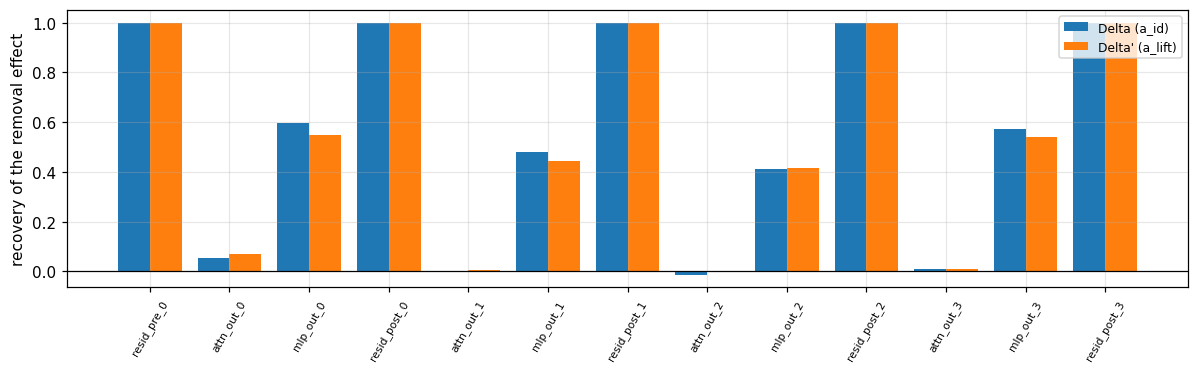

In [17]:
PROFILE_SITES = ["resid_pre_0"] + [f"{kind}_{l}" for l in range(N_LAYERS) for kind in ["attn_out", "mlp_out", "resid_post"]]


@torch.no_grad()
def removal_profile(model, table, other_columns):
    """Per-event Delta (clean, corrupted, and patched at each site) for each 'other action' column."""
    out = {column: {"clean": [], "corrupt": [], **{site: [] for site in PROFILE_SITES}} for column in other_columns}
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE)
        clean_logits, clean_cache = hooks.forward(model, inputs, capture=PROFILE_SITES)
        corrupt_inputs = interventions.remove_feature(inputs, IDENTITY, positions)
        corrupt_logits, _ = hooks.forward(model, corrupt_inputs)
        patched = {site: mi_metrics.at_target(hooks.forward(model, corrupt_inputs,
                                                             replace={site: hooks.copy_at(clean_cache[site], positions)})[0], positions)
                   for site in PROFILE_SITES}
        for column in other_columns:
            a_other = torch.as_tensor(chunk[column].to_numpy(), device=DEVICE)
            out[column]["clean"].append(mi_metrics.delta(mi_metrics.at_target(clean_logits, positions), a_ctx, a_other))
            out[column]["corrupt"].append(mi_metrics.delta(mi_metrics.at_target(corrupt_logits, positions), a_ctx, a_other))
            for site in PROFILE_SITES:
                out[column][site].append(mi_metrics.delta(patched[site], a_ctx, a_other))
    return {column: {key: np.concatenate(values) for key, values in parts.items()} for column, parts in out.items()}


def profile_table(runs, table, keep=None, label=""):
    keep = np.ones(len(table), dtype=bool) if keep is None else keep
    matches = table["match_id"].to_numpy()[keep]
    rows = []
    for site in PROFILE_SITES:
        result = mi_metrics.pooled_recovery(runs[site][keep] - runs["corrupt"][keep], runs["clean"][keep] - runs["corrupt"][keep],
                                            matches, N_BOOT)
        rows.append({"subset": label, "site": site, "recovery": result["recovery"], "CI low": result["ci_low"], "CI high": result["ci_high"]})
    return pd.DataFrame(rows)


profile_runs = removal_profile(MODEL, p_lift, ["a_id", "a_lift"])
estimation_mask = (p_lift["half"] == "estimation").to_numpy()
profile_id = profile_table(profile_runs["a_id"], p_lift, estimation_mask, "Delta (a_id), estimation")
profile_lift = profile_table(profile_runs["a_lift"], p_lift, estimation_mask, "Delta' (a_lift), estimation")
profiles = pd.concat([profile_id, profile_lift], ignore_index=True)
profiles.to_csv(OUT / "results" / "MB15_N3_patching_profile.csv", index=False)
side = profile_id[["site", "recovery"]].merge(profile_lift[["site", "recovery"]], on="site", suffixes=(" Delta", " Delta'"))
side["difference"] = side["recovery Delta'"] - side["recovery Delta"]
print(side.round(4).to_string(index=False))
r = float(np.corrcoef(side["recovery Delta"], side["recovery Delta'"])[0, 1])
same = r > 0.9 and side["difference"].abs().max() <= 0.2
print(f"\ncorrelation of the two profiles over sites: {r:.3f}; largest site difference {side['difference'].abs().max():.3f} "
      f"-> same profile (plan rule): {same}")
fig, axis = plt.subplots(figsize=(11, 3.5))
x = np.arange(len(PROFILE_SITES))
axis.bar(x - 0.2, side["recovery Delta"], 0.4, label="Delta (a_id)")
axis.bar(x + 0.2, side["recovery Delta'"], 0.4, label="Delta' (a_lift)")
axis.set_xticks(x); axis.set_xticklabels(PROFILE_SITES, rotation=60, fontsize=7); axis.axhline(0, color="black", linewidth=0.8)
axis.set_ylabel("recovery of the removal effect"); axis.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB15_N3_profile.png", bbox_inches="tight"); plt.show()

## 12. N6 — Frequent vs less frequent players

The same quantities by the acting player's number of training events (< 1,000 vs ≥ 1,000), estimation half. All numbers are re-readings of the per-event values above; no new model runs.

In [18]:
band_of = dict(zip(controls_frame["event_row"], controls_frame["band"]))
c4_partner = factorials["partner"].assign(beyond=lambda f: np.abs(f["I"]) - np.abs(f["I_floor"]),
                                          band=lambda f: f["event_row"].map(band_of))
n6_rows, n6_profiles = [], []
estimation_frame = controls_frame[controls_frame.half == "estimation"]
for band in sorted(estimation_frame["band"].unique()):
    part = estimation_frame[estimation_frame.band == band]
    m = part["match_id"]
    row = {"band": band, "events": len(part), "players": part["player"].nunique()}
    for name, values in [("removal effect", part["removal effect"]), ("|removal effect|", np.abs(part["removal effect"])),
                         ("C2 vs random vector", np.abs(part["partner: change"]) - part["norm-matched random vector: mean |change|"]),
                         ("C2 vs distribution-matched", np.abs(part["partner: change"]) - part["distribution-matched deviation: mean |change|"]),
                         ("player-specific part", -part["role centroid: change"])]:
        valid = values.notna()
        summary = mi_metrics.summarise(values[valid], m[valid], N_BOOT)
        row[name], row[f"{name} CI low"], row[f"{name} CI high"] = summary["mean"], summary["ci_low"], summary["ci_high"]
    c4_part = c4_partner[(c4_partner.half == "estimation") & (c4_partner.band == band)]
    summary = mi_metrics.summarise(c4_part["beyond"], c4_part["match_id"], N_BOOT)
    row["C4 (partner)"], row["C4 CI low"], row["C4 CI high"] = summary["mean"], summary["ci_low"], summary["ci_high"]
    n6_rows.append(row)
    keep = estimation_mask & (frequency_band(p_lift["player"].to_numpy()) == band)
    if keep.sum() >= 30:
        n6_profiles.append(profile_table(profile_runs["a_id"], p_lift, keep, band))
n6 = pd.DataFrame(n6_rows)
n6.to_csv(OUT / "results" / "MB15_N6_frequency_bands.csv", index=False)
print(n6.round(4).T.to_string())
if n6_profiles:
    n6_profile = pd.concat(n6_profiles, ignore_index=True)
    n6_profile.to_csv(OUT / "results" / "MB15_N6_profiles.csv", index=False)
    print(n6_profile.pivot(index="site", columns="subset", values="recovery").loc[PROFILE_SITES].round(3).to_string())
else:
    n6_profile = pd.DataFrame()

                                                         0                        1
band                                < 1000 training events  >= 1000 training events
events                                                 497                       32
players                                                 40                        2
removal effect                                     -0.1763                  -0.0263
removal effect CI low                               -0.266                   -0.347
removal effect CI high                             -0.0644                   0.2567
|removal effect|                                    0.4728                   0.4048
|removal effect| CI low                             0.3782                   0.3696
|removal effect| CI high                            0.5487                   0.4446
C2 vs random vector                                -0.0928                  -0.0175
C2 vs random vector CI low                         -0.1851                  

## 13. N11 — Rare (player, previous action) pairs

For each P-player event, the number of **training** events with the same acting player and the same previous action. If the model combined a player representation with a context representation compositionally, the player's effect should not collapse on pairs it never saw together. Descriptive; the bins are fixed in the plan.

In [19]:
assert "prev_action" in ENCODED, "BLOCKED: no prev_action input"
train_pairs = pd.DataFrame({"player": ENCODED["player"][torch.as_tensor(TRAIN_ROWS, device=ENCODED["player"].device)].cpu().numpy(),
                            "prev_action": ENCODED["prev_action"][torch.as_tensor(TRAIN_ROWS, device=ENCODED["prev_action"].device)].cpu().numpy()})
pair_counts = train_pairs.groupby(["player", "prev_action"]).size()
event_rows = torch.as_tensor(controls_frame["event_row"].to_numpy(), device=ENCODED["prev_action"].device)
keys = pd.MultiIndex.from_arrays([controls_frame["player"].to_numpy(), ENCODED["prev_action"][event_rows].cpu().numpy()])
counts = pair_counts.reindex(keys).fillna(0).to_numpy()
BINS = [(-1, 0, "0"), (0, 9, "1-9"), (9, 49, "10-49"), (49, np.inf, ">= 50")]
controls_frame["pair count bin"] = pd.cut(counts, [b[0] for b in BINS] + [np.inf], labels=[b[2] for b in BINS]).astype(str)
n11_rows = []
for half in ["estimation", "all validation"]:
    part = controls_frame if half == "all validation" else controls_frame[controls_frame.half == half]
    for label in [b[2] for b in BINS]:
        block = part[part["pair count bin"] == label]
        if len(block) == 0:
            n11_rows.append({"rows": half, "(player, previous action) training count": label, "events": 0})
            continue
        summary = mi_metrics.summarise(np.abs(block["removal effect"]), block["match_id"], N_BOOT)
        n11_rows.append({"rows": half, "(player, previous action) training count": label, "events": len(block),
                         "mean Delta": float(block["Delta"].mean()), "mean removal effect": float(block["removal effect"].mean()),
                         "mean |removal effect|": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"],
                         "mean |partner change|": float(np.abs(block["partner: change"]).mean())})
    rare = np.where(part["pair count bin"].isin(["0", "1-9"]), "rare", np.where(part["pair count bin"] == ">= 50", "common", "middle"))
    difference = group_difference(np.abs(part["removal effect"]), rare, "rare", "common", part["match_id"], N_BOOT_CORR)
    n11_rows.append({"rows": half, "(player, previous action) training count": "rare (0-9) minus common (>= 50), |removal effect|",
                     "events": int((rare != "middle").sum()), "mean |removal effect|": difference["difference"],
                     "CI low": difference["CI low"], "CI high": difference["CI high"]})
n11 = pd.DataFrame(n11_rows)
n11.to_csv(OUT / "results" / "MB15_N11_rare_pairs.csv", index=False)
print(n11.round(4).to_string(index=False))

          rows          (player, previous action) training count  events  mean Delta  mean removal effect  mean |removal effect|  CI low  CI high  mean |partner change|
    estimation                                                 0      10      6.9751              -0.0095                 0.0897  0.0534   0.2012                 0.1501
    estimation                                               1-9     156      6.1371              -0.1819                 0.4774  0.3720   0.5739                 0.6538
    estimation                                             10-49     191      6.2689              -0.1443                 0.4748  0.3603   0.5915                 0.7122
    estimation                                             >= 50     172      5.1935              -0.1885                 0.4760  0.3904   0.5864                 0.5602
    estimation rare (0-9) minus common (>= 50), |removal effect|     338         NaN                  NaN                -0.0220 -0.1633   0.1084          

## 14. Reading the additions together

| If… | then the paper should say… |
|---|---|
| N1 player-specific share is below 0.5 | "identity" results are mostly **role** results; the player adds a smaller part |
| N4 partner beats the distribution-matched control | C2's negative result came from an off-distribution control; learned player content is specific after all |
| N4 partner does not beat it | the player swap moves Δ no more than a realistic fake player: the model is sensitive to the player input, but not to *which* player in a way C2 can detect |
| N2 not reproducible | per-event identity effects are seed-specific; circuit claims about "the identity pathway" should be stated per seed or at player level |
| N3 profile or C1–C4 differ on Δ′ | the main analysis measured "situation vs base rate"; the Δ′ numbers are the ones about the player |

In [20]:
extension_summary = {"plan": "MB15_ext", "N1": n1.to_dict(orient="records"), "N4": n4.to_dict(orient="records"),
                     "N2": n2.to_dict(orient="records"), "N3": n3.to_dict(orient="records"), "N3_C4": c4_lift.to_dict(orient="records"),
                     "N3_profile": side.to_dict(orient="records"), "N6": n6.to_dict(orient="records"),
                     "N6_profiles": n6_profile.to_dict(orient="records"), "N11": n11.to_dict(orient="records"), "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB15_ext_summary.json", extension_summary)
fingerprint.record_files(MANIFEST, {"results/MB15_ext_summary.json": OUT / "results" / "MB15_ext_summary.json"})

{'artifacts/conflict/conflict_set.parquet': {'path': 'artifacts/conflict/conflict_set.parquet',
  'bytes': 1735548,
  'sha256': '19d6197298f38803450ba3befbc0e1b744b6ab900eecb0f6374783c4cf2263b3',
  'recorded_at': '2026-10-05T17:22:56.743259+00:00'},
 'artifacts/conflict/identity_audit/id_mlp_128_64_seed0.pt': {'path': 'artifacts/conflict/identity_audit/id_mlp_128_64_seed0.pt',
  'bytes': 330757,
  'sha256': '590fbc131586f5297fcd9ddfcdf7f2e1c503cf13e9f584142a5c31a10a79339c',
  'recorded_at': '2026-10-05T17:22:56.743711+00:00'},
 'artifacts/conflict/identity_audit/id_mlp_512_512_256_seed0.pt': {'path': 'artifacts/conflict/identity_audit/id_mlp_512_512_256_seed0.pt',
  'bytes': 2280753,
  'sha256': 'eab81928ab7743ddbe2cbdb1dc60d5b584408386e896705115145e7c8a6d62a2',
  'recorded_at': '2026-10-05T17:22:56.746435+00:00'},
 'artifacts/conflict/predictions/test_probs.parquet': {'path': 'artifacts/conflict/predictions/test_probs.parquet',
  'bytes': 7982855,
  'sha256': 'd21c146acd76ee17cb82670b

## 15. Summary and integrity

In [21]:
summary = {"status": PLAN["status"], "calibration": calibration.to_dict(orient="records"),
           "history": history_table.to_dict(orient="records"),
           "identity_under_edits": identity_under_edits.to_dict(orient="records"),
           "interaction_controls": interaction.to_dict(orient="records"),
           "single_factor": single.to_dict(orient="records"), "strata": strata.to_dict(orient="records"),
           "inference_removal": inference_removal.to_dict(orient="records"), "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB15_summary.json", summary)
fingerprint.record_files(MANIFEST, {"results/MB15_summary.json": OUT / "results" / "MB15_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB15", "experiment": "calibration, history, interaction controls, strata, inference removal",
                                "seed": PRIMARY_SEED, "run_mode": RUN_MODE})
est = history_table[history_table.subset == "P-all, estimation half"].set_index("edit")
share = est.loc["history swap", "mean |change in Delta|"] / est.loc["whole-context swap", "mean |change in Delta|"]
print(f"Q2 reading rule: history swap / whole-context swap on the estimation half = {share:.3f} "
      f"({'below' if share < 0.10 else 'not below'} the 0.10 line in the plan)")
row = interaction[(interaction.half == "estimation") & (interaction["player B"] == "partner minus random vector (paired)")].iloc[0]
print(f"Q3 reading rule: partner minus random vector = {row['mean |I| - |I_floor|']:.3f} [{row['CI low']:.3f}, {row['CI high']:.3f}] "
      f"-> player-specific: {row['CI low'] > 0}")

Q2 reading rule: history swap / whole-context swap on the estimation half = 0.094 (below the 0.10 line in the plan)
Q3 reading rule: partner minus random vector = -0.144 [-0.243, -0.015] -> player-specific: False


In [22]:
verified_at_end = fingerprint.verify_files(MANIFEST)
manifest_after = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
changed = sorted(name for name in manifest_before if manifest_after.get(name) != manifest_before[name])
print(f"manifest entries verified at the end: {len(verified_at_end)}")
print("earlier entries whose fingerprint changed during this notebook:", changed if changed else "none")
assert not changed, "BLOCKED: an earlier Track B file changed while this notebook ran."
test_log = OUT / "logs" / "test_access_log.jsonl"
test_lines = len(test_log.read_text().strip().splitlines()) if test_log.exists() and test_log.read_text().strip() else 0
print(f"test accesses recorded so far: {test_lines} (MB12 recorded exactly one; this notebook adds none)")

manifest entries verified at the end: 86
earlier entries whose fingerprint changed during this notebook: none
test accesses recorded so far: 1 (MB12 recorded exactly one; this notebook adds none)


**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- What was observed:
- What it supports / contradicts:
- What it does not establish:
- Evidence label: